In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
df_clima = pd.read_csv('dias_consecutivos_seca_sp_2022.csv')
df_agua = pd.read_csv(
    'perdaDeAgua.csv',
    sep=';',
    encoding='latin1',
    skiprows=1,
    header=None,
    names=[
        'id_municipio',
        'municipio',
        'estado',
        'ano_referencia',
        'id_prestador',
        'prestador',
        'sigla_prestador',
        'abrangencia',
        'tipo_servico',
        'natureza_juridica',
        'indice_perdas_distribuicao'
    ],
    usecols=range(11),
    decimal=','
)
df_renda = pd.read_csv(
    'rendaPerCapitaSP.csv',
    skiprows=6,
    header=None,
    names=['id_municipio', 'municipio', 'grupo_idade', 'renda_per_capita'],
    encoding='utf-8-sig'
)

# 2. Inspecionando as colunas e os primeiros registros
display("--- Dados Climáticos (CDD) ---", df_clima.head())
display("--- Dados de Perda de Água (SNIS) ---", df_agua.head())
display("--- Dados de Renda (IBGE) ---", df_renda.head())

'--- Dados Climáticos (CDD) ---'

,id_municipio,max_dias_consecutivos_seca
0,3506003,25
1,3504503,61
2,3521002,17
3,3522406,40
4,3542305,8


'--- Dados de Perda de Água (SNIS) ---'

,id_municipio,municipio,estado,ano_referencia,id_prestador,prestador,sigla_prestador,abrangencia,tipo_servico,natureza_juridica,indice_perdas_distribuicao
0,350010,Adamantina,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,23.85
1,350020,Adolfo,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,9.72
2,350030,Aguaí,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,66.99
3,350040,Águas da Prata,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,35.38
4,350050,Águas de Lindóia,SP,2022,35005011,Saneamento Ambiental de Águas de Lindóia,SAAE,Local,Água e Esgoto,Autarquia,40.03


'--- Dados de Renda (IBGE) ---'

,id_municipio,municipio,grupo_idade,renda_per_capita
0,3500105,Adamantina (SP),Total,1868.26
1,3500204,Adolfo (SP),Total,1514.80
2,3500303,Aguaí (SP),Total,1321.67
3,3500402,Águas da Prata (SP),Total,1684.99
4,3500501,Águas de Lindóia (SP),Total,1742.52


## Otimizacao de memoria dos datasets

In [18]:
def otimizar_memoria(df):
    memoria_antes = df.memory_usage(deep=True).sum() / 1024**2
    
    for col in df.columns:
        serie = df[col]
        
        if pd.api.types.is_integer_dtype(serie):
            c_min = serie.min()
            c_max = serie.max()
            
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = serie.astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = serie.astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = serie.astype(np.int32)
            else:
                df[col] = serie.astype(np.int64)
        elif pd.api.types.is_float_dtype(serie):
            c_min = serie.min()
            c_max = serie.max()
            
            if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                df[col] = serie.astype(np.float16)
            elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = serie.astype(np.float32)
            else:
                df[col] = serie.astype(np.float64)
                    
    memoria_depois = df.memory_usage(deep=True).sum() / 1024**2
    print(f"Memória reduzida de {memoria_antes:.2f} MB para {memoria_depois:.2f} MB")
    return df

In [19]:


# Otimização de memória em cada dataframe
df_clima = otimizar_memoria(df_clima)
df_agua = otimizar_memoria(df_agua)
df_renda = otimizar_memoria(df_renda)

# Padronizar o nome da coluna de chave primária para o merge futuro
# Substitua 'codigo_ibge' pelo nome real da coluna que identifica o município em cada CSV
coluna_chave = 'id_municipio' 
# df_clima.rename(columns={'NOME_ANTIGO': coluna_chave}, inplace=True)
# df_agua.rename(columns={'NOME_ANTIGO': coluna_chave}, inplace=True)
# df_renda.rename(columns={'NOME_ANTIGO': coluna_chave}, inplace=True)

# Verificação inicial de nulos e tipos (MCAR, MAR, MNAR)
print("--- Nulos no Clima --- \n", df_clima.isna().sum())
print("--- Nulos na Água --- \n", df_agua.isna().sum())
print("--- Nulos na Renda --- \n", df_renda.isna().sum())

Memória reduzida de 0.00 MB para 0.00 MB
Memória reduzida de 0.42 MB para 0.42 MB
Memória reduzida de 0.12 MB para 0.12 MB
--- Nulos no Clima --- 
 id_municipio                  0
max_dias_consecutivos_seca    0
dtype: int64
--- Nulos na Água --- 
 id_municipio                  0
municipio                     0
estado                        0
ano_referencia                0
id_prestador                  0
prestador                     0
sigla_prestador               0
abrangencia                   0
tipo_servico                  0
natureza_juridica             0
indice_perdas_distribuicao    4
dtype: int64
--- Nulos na Renda --- 
 id_municipio         1
municipio           10
grupo_idade         17
renda_per_capita    17
dtype: int64


In [20]:
# Removendo os 4 nulos do índice de perdas
df_agua.dropna(subset=['indice_perdas_distribuicao'], inplace=True)

# Removendo os 17 nulos da renda e 1 nulo do id_municipio
df_renda.dropna(subset=['renda_per_capita', 'id_municipio'], inplace=True)

# O id_municipio no df_renda provavelmente virou float por causa do nulo, vamos garantir que seja int64
df_renda['id_municipio'] = df_renda['id_municipio'].astype('int64')

print(f"Linhas restantes em Água: {len(df_agua)}")
print(f"Linhas restantes em Renda: {len(df_renda)}")

Linhas restantes em Água: 643
Linhas restantes em Renda: 645


In [23]:
def verificar_outliers_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    # Filtra apenas os registros que estão fora dos limites
    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]
    percentual = (len(outliers) / len(df)) * 100
    
    print(f"-> {coluna}: {len(outliers)} outliers identificados ({percentual:.2f}% da base)")
    
    # Se quiser ver quais são os piores valores, descomente a linha abaixo:
    # display(outliers.sort_values(by=coluna, ascending=False).head())

print("=== Verificação Estatística de Outliers (Método IQR) ===")
verificar_outliers_iqr(df_renda, 'renda_per_capita')
verificar_outliers_iqr(df_agua, 'indice_perdas_distribuicao')
verificar_outliers_iqr(df_clima, 'max_dias_consecutivos_seca')

=== Verificação Estatística de Outliers (Método IQR) ===
-> renda_per_capita: 24 outliers identificados (3.72% da base)
-> indice_perdas_distribuicao: 16 outliers identificados (2.49% da base)
-> max_dias_consecutivos_seca: 2 outliers identificados (5.26% da base)


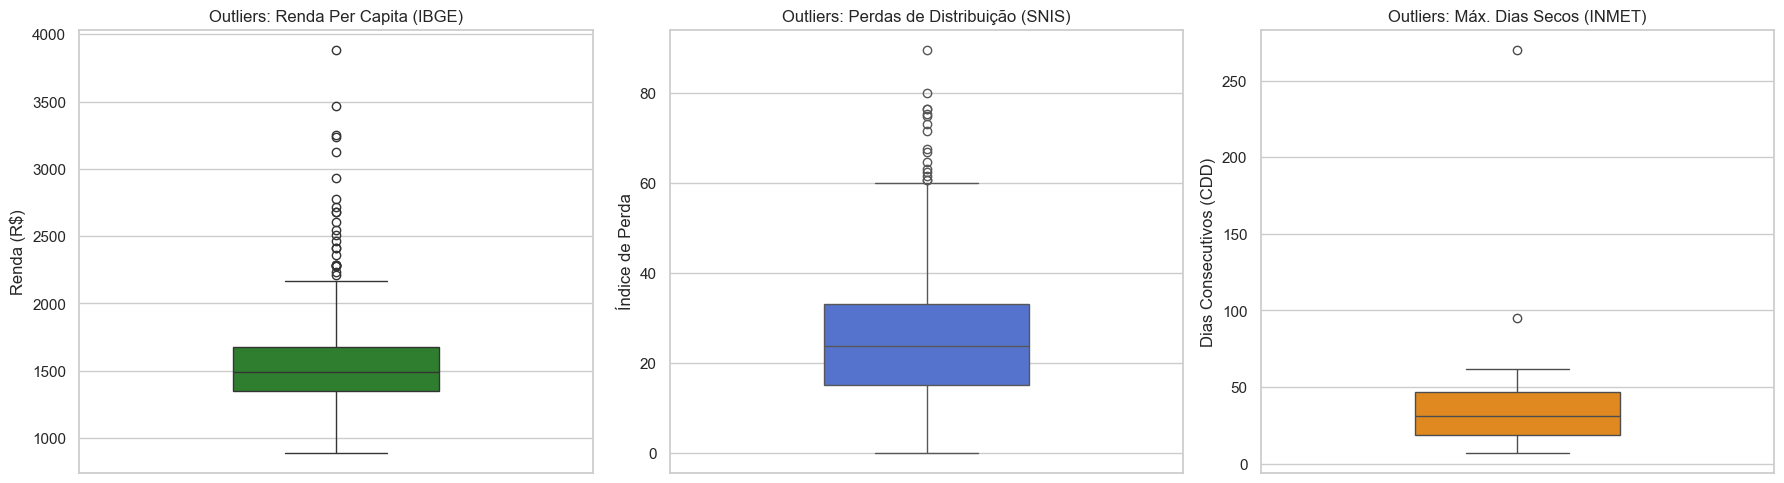

In [24]:
# Criando uma figura com 3 gráficos (subplots) lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Boxplot da Renda Per Capita
sns.boxplot(y=df_renda['renda_per_capita'], ax=axes[0], color='forestgreen', width=0.4)
axes[0].set_title('Outliers: Renda Per Capita (IBGE)')
axes[0].set_ylabel('Renda (R$)')

# 2. Boxplot das Perdas de Distribuição
sns.boxplot(y=df_agua['indice_perdas_distribuicao'], ax=axes[1], color='royalblue', width=0.4)
axes[1].set_title('Outliers: Perdas de Distribuição (SNIS)')
axes[1].set_ylabel('Índice de Perda')

# 3. Boxplot do Clima (CDD)
sns.boxplot(y=df_clima['max_dias_consecutivos_seca'], ax=axes[2], color='darkorange', width=0.4)
axes[2].set_title('Outliers: Máx. Dias Secos (INMET)')
axes[2].set_ylabel('Dias Consecutivos (CDD)')

# Ajusta o espaçamento para não sobrepor os títulos
plt.tight_layout()
plt.show()

In [26]:
# 1. TRATAMENTO DO CLIMA (Remover o erro absurdo antes do KNN)
# Cortamos qualquer registro com mais de 150 dias sem chuva (que elimina aquele ponto de >250)
df_clima = df_clima[df_clima['max_dias_consecutivos_seca'] < 150]

# (Após esse corte, você deve rodar aquela célula do merge e do KNNImputer que fizemos antes)


# 2. TRATAMENTO DE RENDA E PERDAS (Winsorização / Capping)
# Essa função não deleta o município, apenas "tosa" o valor extremo no limite do bigode do boxplot
def aplicar_capping_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    
    # Substitui os valores acima do limite pelo próprio valor do limite
    df[coluna] = np.where(df[coluna] > limite_superior, limite_superior, df[coluna])
    return df


c:\Users\Du\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\Du\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\nanops.py:1037: RuntimeWarning: overflow encountered in cast
  result = result.astype(dtype, copy=False)


'Estatísticas - Renda (IBGE):'

count     645.0
mean        inf
std         inf
min       888.5
25%      1349.0
50%      1488.0
75%      1677.0
max      3884.0
Name: renda_per_capita, dtype: float64

'Estatísticas - Perdas (SNIS):'

count    643.00
mean      25.45
std       14.52
min        0.00
25%       15.17
50%       23.84
75%       33.16
max       89.62
Name: indice_perdas_distribuicao, dtype: float64

'Estatísticas - Clima (INMET):'

count    37.00
mean     32.86
std      18.89
min       7.00
25%      18.00
50%      30.00
75%      42.00
max      95.00
Name: max_dias_consecutivos_seca, dtype: float64

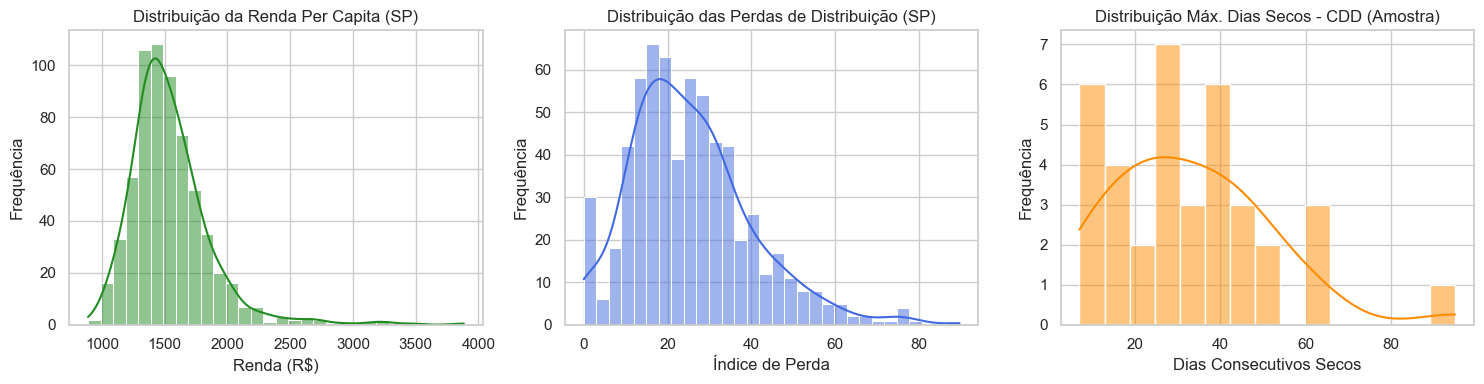

In [29]:
sns.set_theme(style="whitegrid")

# 1. Estatísticas Descritivas
display("Estatísticas - Renda (IBGE):", df_renda['renda_per_capita'].describe().round(2))
display("Estatísticas - Perdas (SNIS):", df_agua['indice_perdas_distribuicao'].describe().round(2))
display("Estatísticas - Clima (INMET):", df_clima['max_dias_consecutivos_seca'].describe().round(2))

# 2. Histogramas (Grid 1x3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histograma: Renda
sns.histplot(df_renda['renda_per_capita'], bins=30, kde=True, ax=axes[0], color='forestgreen')
axes[0].set_title('Distribuição da Renda Per Capita (SP)')
axes[0].set_xlabel('Renda (R$)')
axes[0].set_ylabel('Frequência')

# Histograma: Perdas
sns.histplot(df_agua['indice_perdas_distribuicao'], bins=30, kde=True, ax=axes[1], color='royalblue')
axes[1].set_title('Distribuição das Perdas de Distribuição (SP)')
axes[1].set_xlabel('Índice de Perda')
axes[1].set_ylabel('Frequência')

# Histograma: Clima
sns.histplot(df_clima['max_dias_consecutivos_seca'], bins=15, kde=True, ax=axes[2], color='darkorange')
axes[2].set_title('Distribuição Máx. Dias Secos - CDD (Amostra)')
axes[2].set_xlabel('Dias Consecutivos Secos')
axes[2].set_ylabel('Frequência')

plt.tight_layout()
plt.show()